In [ ]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
# from torchvision.models import 
import torchvision.models as models


import string
from tqdm.notebook import tqdm
import cv2
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import multiprocessing as mp

/home/ubuntu-vilalab/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
csv_data_path = [
    "/home/ubuntu-vilalab/Desktop/setthika/ocr/new_dataset/labels/labels.csv",
    "/home/ubuntu-vilalab/Desktop/setthika/ocr/new_dataset_siemreap/labels/labels.csv",
    "/home/ubuntu-vilalab/Desktop/setthika/ocr/new_dataset_moulight/labels/labels.csv"
    ]
image_data_path = [
    "/home/ubuntu-vilalab/Desktop/setthika/ocr/new_dataset/images/Battambang",
    "/home/ubuntu-vilalab/Desktop/setthika/ocr/new_dataset_siemreap/images/Siemreap",
    "/home/ubuntu-vilalab/Desktop/setthika/ocr/new_dataset_moulight/images/Moulight",
    ]

In [3]:
import pandas as pd
dfs = []
for csv_data_paths in csv_data_path:
    df = pd.read_csv(csv_data_paths)
    dfs.append(df)

df = pd.concat(dfs, ignore_index=True)
df
# df = pd.read_csv(csv_data_path)
# df


,image,label
0,Khmer_txt_1.png,ហេតុដូចម្តេចទើបមានការបង្កើតតាក់ស៊ីក្រហមឬTaxiRo...
1,Khmer_txt_2.png,និយាយទៅខ្ញុំបានសង្កេតពីការវិវត្តរបស់ប្រទេសកម្ព...
2,Khmer_txt_3.png,ខ្ញុំក៏សម្រេចចិត្តដំណើរការក្រុមហ៊ុនផ្តល់សេវាកម...
3,Khmer_txt_4.png,ហេតុអ្វីបានជាតាក់ស៊ីក្រហមត្រូវតែមាននៅកម្ពុជា?
4,Khmer_txt_5.png,តើចំណុចណាដែលធ្វើឲ្យតាក់ស៊ីក្រហមលេចធ្លោជាងក្រុម...
...,...,...
19466,Khmer_txt_19467.png,ពួកគេប្រើប្រាស់ផ្នែកខាងចុងដ៏វែងនេះដើម្បីគោះតួដ...
19467,Khmer_txt_19468.png,សេវាSathapana
19468,Khmer_txt_19469.png,សីលាបើមិនធ្វើមានតែអត់។
19469,Khmer_txt_19470.png,សំនួរការទាញយកhighdefinitionenvironmentv21.zip


In [5]:
df = df.dropna()

def clean_irrelevant(result):    
    result = result.replace('\u200b','')
    result = result.replace('/u200b','')

    # result = result.replace('quot ','')

    return result
df["label"] = df["label"].apply(clean_irrelevant)
# df = df[df['label'].apply(lambda x: len(x) <= 40)]
# df= df.reset_index(drop=True)

df

,image,label
0,Khmer_txt_1.png,ហេតុដូចម្តេចទើបមានការបង្កើតតាក់ស៊ីក្រហមឬTaxiRo...
1,Khmer_txt_2.png,និយាយទៅខ្ញុំបានសង្កេតពីការវិវត្តរបស់ប្រទេសកម្ព...
2,Khmer_txt_3.png,ខ្ញុំក៏សម្រេចចិត្តដំណើរការក្រុមហ៊ុនផ្តល់សេវាកម...
3,Khmer_txt_4.png,ហេតុអ្វីបានជាតាក់ស៊ីក្រហមត្រូវតែមាននៅកម្ពុជា?
4,Khmer_txt_5.png,តើចំណុចណាដែលធ្វើឲ្យតាក់ស៊ីក្រហមលេចធ្លោជាងក្រុម...
...,...,...
19466,Khmer_txt_19467.png,ពួកគេប្រើប្រាស់ផ្នែកខាងចុងដ៏វែងនេះដើម្បីគោះតួដ...
19467,Khmer_txt_19468.png,សេវាSathapana
19468,Khmer_txt_19469.png,សីលាបើមិនធ្វើមានតែអត់។
19469,Khmer_txt_19470.png,សំនួរការទាញយកhighdefinitionenvironmentv21.zip


In [6]:
def check_missing_values(df):
    """
    This function checks if there are any missing values in any row of the DataFrame.
    
    Parameters:
    df (pd.DataFrame): The DataFrame to check for missing values.
    
    Returns:
    bool: True if there are missing values in any row, False otherwise.
    """
    return df.isnull().any(axis=1).any()

if check_missing_values(df):
    print("There are missing values in the DataFrame.")
else:
    print("There are no missing values in the DataFrame.")

There are no missing values in the DataFrame.


In [7]:
datapath_all = df["image"].tolist()
label_all = df["label"].tolist()
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

# print((train_df["Label"]))
def check_missing_values(df):
    """
    This function checks if there are any missing values in any row of the DataFrame.
    
    Parameters:
    df (pd.DataFrame): The DataFrame to check for missing values.
    
    Returns:
    bool: True if there are missing values in any row, False otherwise.
    """
    return df.isnull().any(axis=1).any()
datapath_train = train_df["image"].tolist()
datapath_test = test_df["image"].tolist()

label_train = train_df["label"].tolist()
label_test = test_df["label"].tolist()
label_train[:5]

['ប្រភពបន្ថែមថា៖',
 'លោកPatrickMahoneyគាំទ្រនិងលើកទឹកចិត្តនិស្សិតដែលចាប់អារម្មណ៍លើអាជីពក្នុងវិស័យអប់រំ។',
 'ការវិនិយោគប្រចាំឆ្នាំខាងបច្ចេកវិទ្យាមានដូចជាបន្ទះស្រូបពន្លឺព្រះអាទិត្យថាមពលខ្យល់និងវារីអគ្គិសនីលើសពីឥន្ធនៈហ្វូស៊ីលជាលើកដំបូងពីឆ្នាំ២០១១៕',
 'តាមដានព័ត៌មានទាំងអស់ដែលអ្នកត្រូវការជាមួយនឹងវាលផ្ទាល់ខ្លួន',
 'បញ្ជាការផ្លាស់ប្តូរV']

In [8]:
datapath_train[:5]

['Khmer_txt_5469.png',
 'Khmer_txt_9863.png',
 'Khmer_txt_12984.png',
 'Khmer_txt_17258.png',
 'Khmer_txt_17291.png']

In [ ]:
test_df


In [9]:
print(len(label_train))
print(np.unique([len(image_fn.split(" ")[0]) for image_fn in label_train]))

15576
[  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107 108
 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125 126
 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143 144
 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161 162
 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179 180
 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197 198
 199]


In [10]:
cpu_count = mp.cpu_count()
print(cpu_count)

16


In [11]:
print(len(train_df), len(test_df))

15576 3895


In [12]:
# image_ns = [image_fn.split(".")[0] for image_fn in label_all]
image_ns = [image_fn.split(" ")[0] for image_fn in label_all]


# image_ns = [image_fn[0] for image_fn in label_all]


image_ns = "".join(image_ns)
letters = sorted(list(set(list(image_ns))))
print(len(letters))
print(letters)

172
['!', '$', '%', '&', "'", '(', ')', '+', ',', '-', '.', '/', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', '[', ']', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', '«', '»', 'ç', 'è', 'é', 'ក', 'ខ', 'គ', 'ឃ', 'ង', 'ច', 'ឆ', 'ជ', 'ឈ', 'ញ', 'ដ', 'ឋ', 'ឌ', 'ឍ', 'ណ', 'ត', 'ថ', 'ទ', 'ធ', 'ន', 'ប', 'ផ', 'ព', 'ភ', 'ម', 'យ', 'រ', 'ល', 'វ', 'ស', 'ហ', 'ឡ', 'អ', 'ឥ', 'ឦ', 'ឧ', 'ឩ', 'ឪ', 'ឫ', 'ឬ', 'ឭ', 'ឮ', 'ឯ', 'ឱ', 'ឲ', 'ា', 'ិ', 'ី', 'ឹ', 'ឺ', 'ុ', 'ូ', 'ួ', 'ើ', 'ឿ', 'ៀ', 'េ', 'ែ', 'ៃ', 'ោ', 'ៅ', 'ំ', 'ះ', 'ៈ', '៉', '៊', '់', '៌', '៍', '៎', '៏', '័', '្', '។', '៕', '៖', 'ៗ', '៛', '៝', '០', '១', '២', '៣', '៤', '៥', '៦', '៧', '៨', '៩']


In [13]:
character = [chr(i) for i in range(ord('A'), ord('Z') + 1)]
# print("Character")
# print(character)

#vocabulary = ["."]+["p"]+letters+character + ["g"]
# vocabulary = letters+character
vocabulary = letters


print(len(vocabulary))
# print(vocabulary)
idx2char = {k:v for k,v in enumerate(vocabulary, start=0)}
# print(idx2char)
char2idx = {v:k for k,v in idx2char.items()}
print("All Vocabs")
print(char2idx)

172
All Vocabs
{'!': 0, '$': 1, '%': 2, '&': 3, "'": 4, '(': 5, ')': 6, '+': 7, ',': 8, '-': 9, '.': 10, '/': 11, '0': 12, '1': 13, '2': 14, '3': 15, '4': 16, '5': 17, '6': 18, '7': 19, '8': 20, '9': 21, ':': 22, '?': 23, 'A': 24, 'B': 25, 'C': 26, 'D': 27, 'E': 28, 'F': 29, 'G': 30, 'H': 31, 'I': 32, 'J': 33, 'K': 34, 'L': 35, 'M': 36, 'N': 37, 'O': 38, 'P': 39, 'Q': 40, 'R': 41, 'S': 42, 'T': 43, 'U': 44, 'V': 45, 'W': 46, 'X': 47, 'Y': 48, 'Z': 49, '[': 50, ']': 51, 'a': 52, 'b': 53, 'c': 54, 'd': 55, 'e': 56, 'f': 57, 'g': 58, 'h': 59, 'i': 60, 'j': 61, 'k': 62, 'l': 63, 'm': 64, 'n': 65, 'o': 66, 'p': 67, 'q': 68, 'r': 69, 's': 70, 't': 71, 'u': 72, 'v': 73, 'w': 74, 'x': 75, 'y': 76, 'z': 77, '«': 78, '»': 79, 'ç': 80, 'è': 81, 'é': 82, 'ក': 83, 'ខ': 84, 'គ': 85, 'ឃ': 86, 'ង': 87, 'ច': 88, 'ឆ': 89, 'ជ': 90, 'ឈ': 91, 'ញ': 92, 'ដ': 93, 'ឋ': 94, 'ឌ': 95, 'ឍ': 96, 'ណ': 97, 'ត': 98, 'ថ': 99, 'ទ': 100, 'ធ': 101, 'ន': 102, 'ប': 103, 'ផ': 104, 'ព': 105, 'ភ': 106, 'ម': 107, 'យ': 108, 'រ':

In [14]:
batch_size = 16

In [15]:
class CAPTCHADataset(Dataset):
    
    def __init__(self, data_dirs, image_fns):
        self.data_dirs = data_dirs
        self.image_fns = image_fns
        
    def __len__(self):
        return len(self.image_fns)
    
    def __getitem__(self, index):
        image_fn = self.image_fns[index]
        image = None
        for data_dir in self.data_dirs:
            image_fp = os.path.join(data_dir, image_fn)
            if os.path.exists(image_fp):
                image = Image.open(image_fp).convert('RGB')
                break
        
        if image is None:
            raise FileNotFoundError(f"Image file '{image_fn}' not found in any of the specified directories.")
        
        image = self.transform(image)
        
        # Assuming the label is obtained from a DataFrame
        text = df.loc[df['image'] == image_fn, 'label'].iloc[0]
        
        return image, text
    
    def transform(self, image):
        transform_ops = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
        ])
        return transform_ops(image)


In [ ]:
class CAPTCHADataset(Dataset):
    
    def __init__(self, data_dir, image_fns):
        self.data_dir = data_dir
        self.image_fns = image_fns
        
    def __len__(self):
        return len(self.image_fns)
    
    def __getitem__(self, index):
        image_fn = self.image_fns[index]
        image_fp = os.path.join(self.data_dir, image_fn)
        #image_fp = image_fp + ".png"
        image = Image.open(image_fp).convert('RGB')
        image = self.transform(image)
#         text = image_fn.split(".")[0]
        text = df.loc[df['image']==image_fn,"label"].iloc[0]
#         print(text)
        
        return image, text
    
    def transform(self, image):
        
        transform_ops = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
        ])
        return transform_ops(image)

In [16]:
trainset = CAPTCHADataset(image_data_path, datapath_train) 
testset = CAPTCHADataset(image_data_path, datapath_test)
train_loader = DataLoader(trainset, batch_size=batch_size, num_workers=cpu_count, shuffle=True)
test_loader = DataLoader(testset, batch_size=batch_size, num_workers=cpu_count, shuffle=False)
print(len(train_loader), len(test_loader))

974 244


In [17]:
image_batch, text_batch = next(iter(train_loader))
print(image_batch.size(), text_batch)

torch.Size([16, 3, 100, 1400]) ('មិនអាចផ្លាស់ទីការងារត្រូវធ្វើទៅខ្លួនវាឬទៅកូនវាបានឡើយ។', 'យោធាថៃនឹងលក់អង្ករចេញ៥សែនតោនក្នុងមួយខែ', 'ការគណៈរដ្ឋមន្រ្តីការធានាឧបករណ៍ដែលធ្វើការនៅក្នុងច្រើនបំផុត', 'ម៉ាស៊ីនបម្រើរបស់Windows', 'កំណត់finalCountអោយខ្ញុំចំនួនចុងក្រោយរាប់', 'សារអេឡិចត្រូនិកៈtboungkhmumtax.gov.kh', 'លោកIzumiDevalierសេដ្ឋវិទូជប៉ុនប្រចាំក្រុមហ៊ុនHSBCHoldingsPlcនៅទីក្រុងហុងកុងបានថ្លែងថា៖', 'លោកHagueបានបន្តឲ្យដឹងថា៖', 'ក្នុងមួយឆ្នាំទ្រព្យដែលនៅអតិថិជនមិនមកលោះនោះមានមិនលើសពី៥ភាគរយទេ។', 'អ៊ុយដាព័រtripura.kgm', 'មើលទៅមែនអត់', 'អាគុយកុំព្យទ័រម៉ាកMacBookAir11A1465A1370', 'កត្តានេះជួយបានច្រើនក្នុងការទាក់ទាញក្រុមហ៊ុនថ្មីៗ»។', 'ពេលវេលានាំមុខ55ថ្ងៃ', 'ទំព័រដើមThistlegormEgypt2018', 'តើអ៊ីវីគឺជាអ្វី?')


In [18]:
num_chars = len(char2idx)
print(num_chars)
rnn_hidden_size = 512
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

172
cuda


In [19]:
class OCR_CNN_GRU(nn.Module):
    def __init__(self, num_chars=158, rnn_hidden_size=256, dropout=0.1):
        super(OCR_CNN_GRU, self).__init__()
        self.num_chars = num_chars
        self.rnn_hidden_size = rnn_hidden_size
        self.dropout = dropout
        
        # CNN layers
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=(3, 3), padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=(2, 2), stride=2),
            
            nn.Conv2d(64, 128, kernel_size=(3, 3), padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=(2, 2), stride=2),
            
#             nn.Conv2d(128, 256, kernel_size=(3, 3), padding=1),
#             nn.BatchNorm2d(256),
#             nn.ReLU(inplace=True),
#             nn.MaxPool2d(kernel_size=(2, 2), stride=2),
            
#             nn.Conv2d(256, 512, kernel_size=(3, 3), padding=1),
#             nn.BatchNorm2d(512),
#             nn.ReLU(inplace=True),
#             nn.MaxPool2d(kernel_size=(2, 2), stride=2),
            
#             nn.Conv2d(512, 1024, kernel_size=(3, 3), padding=1),
#             nn.BatchNorm2d(1024),
#             nn.ReLU(inplace=True),
#             nn.MaxPool2d(kernel_size=(2, 2), stride=2),
        )
        
        # Linear layer to reduce dimension before feeding into GRU
#         self.linear1 = nn.Linear(512 * 8, rnn_hidden_size)
        self.linear1 = nn.Linear(3200, rnn_hidden_size)


        
        # GRU layers
        self.gru = nn.GRU(
            input_size=rnn_hidden_size, 
            hidden_size=rnn_hidden_size, 
            num_layers=2, 
            bidirectional=True, 
            batch_first=True
        )
        
        # Output layer
        self.linear2 = nn.Linear(rnn_hidden_size * 2, num_chars)
        
    def forward(self, x):
        x = self.cnn(x)
        
        # Reshape from [batch_size, channels, height, width] to [batch_size, width, channels * height]
        batch_size, channels, height, width = x.size()
        x = x.permute(0, 3, 1, 2).contiguous().view(batch_size, width, -1)
        
        # Linear layer to reduce dimension
        x = self.linear1(x)
        
        # GRU layers
        x, _ = self.gru(x)
        
        # Output layer
        x = self.linear2(x)
        
        # Transpose to get the shape [sequence_length, batch_size, num_classes]
        x = x.transpose(0, 1)
        
        return x

def weights_init(m):
    if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight)
        if m.bias is not None:
            m.bias.data.fill_(0.01)
    elif isinstance(m, nn.BatchNorm2d):
        m.weight.data.fill_(1.0)
        m.bias.data.fill_(0.01)




In [20]:
crnn = OCR_CNN_GRU(num_chars, rnn_hidden_size=rnn_hidden_size)
crnn.apply(weights_init)
crnn = crnn.to(device)
text_batch_logits = crnn(image_batch.to(device))
print(text_batch)
print(text_batch_logits.shape)

('មិនអាចផ្លាស់ទីការងារត្រូវធ្វើទៅខ្លួនវាឬទៅកូនវាបានឡើយ។', 'យោធាថៃនឹងលក់អង្ករចេញ៥សែនតោនក្នុងមួយខែ', 'ការគណៈរដ្ឋមន្រ្តីការធានាឧបករណ៍ដែលធ្វើការនៅក្នុងច្រើនបំផុត', 'ម៉ាស៊ីនបម្រើរបស់Windows', 'កំណត់finalCountអោយខ្ញុំចំនួនចុងក្រោយរាប់', 'សារអេឡិចត្រូនិកៈtboungkhmumtax.gov.kh', 'លោកIzumiDevalierសេដ្ឋវិទូជប៉ុនប្រចាំក្រុមហ៊ុនHSBCHoldingsPlcនៅទីក្រុងហុងកុងបានថ្លែងថា៖', 'លោកHagueបានបន្តឲ្យដឹងថា៖', 'ក្នុងមួយឆ្នាំទ្រព្យដែលនៅអតិថិជនមិនមកលោះនោះមានមិនលើសពី៥ភាគរយទេ។', 'អ៊ុយដាព័រtripura.kgm', 'មើលទៅមែនអត់', 'អាគុយកុំព្យទ័រម៉ាកMacBookAir11A1465A1370', 'កត្តានេះជួយបានច្រើនក្នុងការទាក់ទាញក្រុមហ៊ុនថ្មីៗ»។', 'ពេលវេលានាំមុខ55ថ្ងៃ', 'ទំព័រដើមThistlegormEgypt2018', 'តើអ៊ីវីគឺជាអ្វី?')
torch.Size([350, 16, 172])


In [21]:
criterion = nn.CTCLoss(blank=0)
def encode_text_batch(text_batch):
    
    text_batch_targets_lens = [len(text) for text in text_batch]
    text_batch_targets_lens = torch.IntTensor(text_batch_targets_lens)
    
    text_batch_concat = "".join(text_batch)
    text_batch_targets = [char2idx[c] for c in text_batch_concat]
    text_batch_targets = torch.IntTensor(text_batch_targets)
    
    return text_batch_targets, text_batch_targets_lens

In [22]:
def compute_loss(text_batch, text_batch_logits):
    """
    text_batch: list of strings of length equal to batch size
    text_batch_logits: Tensor of size([T, batch_size, num_classes])
    """
    text_batch_logps = F.log_softmax(text_batch_logits, 2) # [T, batch_size, num_classes]  
    text_batch_logps_lens = torch.full(size=(text_batch_logps.size(1),), 
                                       fill_value=text_batch_logps.size(0), 
                                       dtype=torch.int32).to(device) # [batch_size] 
    #print(text_batch_logps.shape)
    #print(text_batch_logps_lens) 
    text_batch_targets, text_batch_targets_lens = encode_text_batch(text_batch)
    #print(text_batch_targets)
    #print(text_batch_targets_lens)
    loss = criterion(text_batch_logps, text_batch_targets, text_batch_logps_lens, text_batch_targets_lens)

    return loss

compute_loss(text_batch, text_batch_logits)

tensor(54.6041, device='cuda:0', grad_fn=<MeanBackward0>)

In [23]:
num_epochs = 20
lr = 1e-4
weight_decay = 1e-3
clip_norm = 5

In [24]:
optimizer = optim.Adam(crnn.parameters(), lr=lr, weight_decay=weight_decay)
lr_scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, verbose=True, patience=5)

/home/ubuntu-vilalab/.local/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:28: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn("The verbose parameter is deprecated. Please use get_last_lr() "


In [25]:
import numpy as np
import torch.nn as nn
from tqdm.notebook import tqdm  # Use tqdm.notebook for better support in notebooks

# Assuming other necessary imports and initializations are already done

epoch_losses = []
iteration_losses = []
num_updates_epochs = []
validation_losses = []
best_val_loss = float('inf')
epochs_no_improve = 0

# Function to save checkpoints
def save_checkpoint(state, filename):
    torch.save(state, filename)

# Main training loop
for epoch in range(1, num_epochs + 1):
    epoch_loss_list = []
    num_updates_epoch = 0
    crnn.train()  # Set model to training mode

    # Training step with a single progress bar
    train_loader_tqdm = tqdm(train_loader, desc=f"Epoch {epoch}/{num_epochs} - Training", leave=True)
    for image_batch, text_batch in train_loader_tqdm:
        optimizer.zero_grad()
        text_batch_logits = crnn(image_batch.to(device))
        loss = compute_loss(text_batch, text_batch_logits)
        iteration_loss = loss.item()

        if np.isnan(iteration_loss) or np.isinf(iteration_loss):
            continue

        num_updates_epoch += 1
        iteration_losses.append(iteration_loss)
        epoch_loss_list.append(iteration_loss)
        loss.backward()
        nn.utils.clip_grad_norm_(crnn.parameters(), clip_norm)
        optimizer.step()

        # Update progress bar with the current loss
        train_loader_tqdm.set_postfix(loss=iteration_loss)

    epoch_loss = np.mean(epoch_loss_list)
    epoch_losses.append(epoch_loss)
    num_updates_epochs.append(num_updates_epoch)

    # Validation step with a single progress bar
    crnn.eval()  # Set model to evaluation mode
    with torch.no_grad():
        val_losses = []
        val_loader_tqdm = tqdm(test_loader, desc=f"Epoch {epoch}/{num_epochs} - Validation", leave=True)
        for image_batch, text_batch in val_loader_tqdm:
            text_batch_logits = crnn(image_batch.to(device))
            val_loss = compute_loss(text_batch, text_batch_logits)
            val_losses.append(val_loss.item())
            val_loader_tqdm.set_postfix(val_loss=val_loss.item())

        validation_loss = np.mean(val_losses)
    validation_losses.append(validation_loss)

    # Early stopping and saving the best model
    if validation_loss < best_val_loss:
        best_val_loss = validation_loss
        save_checkpoint({
            'epoch': epoch,
            'model_state_dict': crnn.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_val_loss': best_val_loss,
            'epoch_losses': epoch_losses,
            'iteration_losses': iteration_losses,
            'num_updates_epochs': num_updates_epochs,
            'validation_losses': validation_losses
        }, f'/home/ubuntu-vilalab/Desktop/setthika/ocr/checkpoint/checkpoint_best.pth')  # Save the best model checkpoint
        epochs_no_improve = 0  # Reset the counter for early stopping
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= num_epochs:
            print(f'Early stopping triggered after {epoch} epochs.')
            break  # Early stopping condition met

    print(f"Epoch: {epoch}    Loss: {epoch_loss:.4f}    NumUpdates: {num_updates_epoch}    ValLoss: {validation_loss:.4f}")
    lr_scheduler.step(validation_loss)


Epoch 1/20 - Training:   0%|          | 0/974 [00:00<?, ?it/s]

Epoch 1/20 - Validation:   0%|          | 0/244 [00:00<?, ?it/s]

Epoch: 1    Loss: 2.0862    NumUpdates: 974    ValLoss: 0.7163


Epoch 2/20 - Training:   0%|          | 0/974 [00:00<?, ?it/s]

Epoch 2/20 - Validation:   0%|          | 0/244 [00:00<?, ?it/s]

Epoch: 2    Loss: 0.5132    NumUpdates: 974    ValLoss: 0.3973


... (50 outputs left out)

Epoch: 19    Loss: 0.1097    NumUpdates: 974    ValLoss: 0.1426


Epoch 20/20 - Training:   0%|          | 0/974 [00:00<?, ?it/s]

Epoch 20/20 - Validation:   0%|          | 0/244 [00:00<?, ?it/s]

Epoch: 20    Loss: 0.1091    NumUpdates: 974    ValLoss: 0.1375


In [ ]:
import numpy as np
import torch.nn as nn
from tqdm.notebook import tqdm  # Use tqdm.notebook for better support in notebooks

# Assuming other necessary imports and initializations are already done

epoch_losses = []
iteration_losses = []
num_updates_epochs = []
validation_losses = []
best_val_loss = float('inf')
epochs_no_improve = 0

# Main training loop
for epoch in range(1, num_epochs + 1):
    epoch_loss_list = []
    num_updates_epoch = 0
    crnn.train()  # Set model to training mode

    # Training step with a single progress bar
    train_loader_tqdm = tqdm(train_loader, desc=f"Epoch {epoch}/{num_epochs} - Training", leave=True)
    for image_batch, text_batch in train_loader_tqdm:
        optimizer.zero_grad()
        text_batch_logits = crnn(image_batch.to(device))
        loss = compute_loss(text_batch, text_batch_logits)
        iteration_loss = loss.item()

        if np.isnan(iteration_loss) or np.isinf(iteration_loss):
            continue

        num_updates_epoch += 1
        iteration_losses.append(iteration_loss)
        epoch_loss_list.append(iteration_loss)
        loss.backward()
        nn.utils.clip_grad_norm_(crnn.parameters(), clip_norm)
        optimizer.step()

        # Update progress bar with the current loss
        train_loader_tqdm.set_postfix(loss=iteration_loss)

    epoch_loss = np.mean(epoch_loss_list)
    epoch_losses.append(epoch_loss)
    num_updates_epochs.append(num_updates_epoch)

    # Validation step with a single progress bar
    crnn.eval()  # Set model to evaluation mode
    with torch.no_grad():
        val_losses = []
        val_loader_tqdm = tqdm(test_loader, desc=f"Epoch {epoch}/{num_epochs} - Validation", leave=True)
        for image_batch, text_batch in val_loader_tqdm:
            text_batch_logits = crnn(image_batch.to(device))
            val_loss = compute_loss(text_batch, text_batch_logits)
            val_losses.append(val_loss.item())
            val_loader_tqdm.set_postfix(val_loss=val_loss.item())

        validation_loss = np.mean(val_losses)
    validation_losses.append(validation_loss)

    # Early stopping and saving the best model
    if validation_loss < best_val_loss:
        best_val_loss = validation_loss
        torch.save(crnn.state_dict(), '/home/ubuntu-vilalab/Desktop/setthika/ocr/checkpoint/checkpoint.pth')  # Save the best model
        epochs_no_improve = 0  # Reset the counter for early stopping
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= num_epochs:
            print(f'Early stopping triggered after {epoch} epochs.')
            break  # Early stopping condition met

    print(f"Epoch: {epoch}    Loss: {epoch_loss:.4f}    NumUpdates: {num_updates_epoch}    ValLoss: {validation_loss:.4f}")
    lr_scheduler.step(validation_loss)


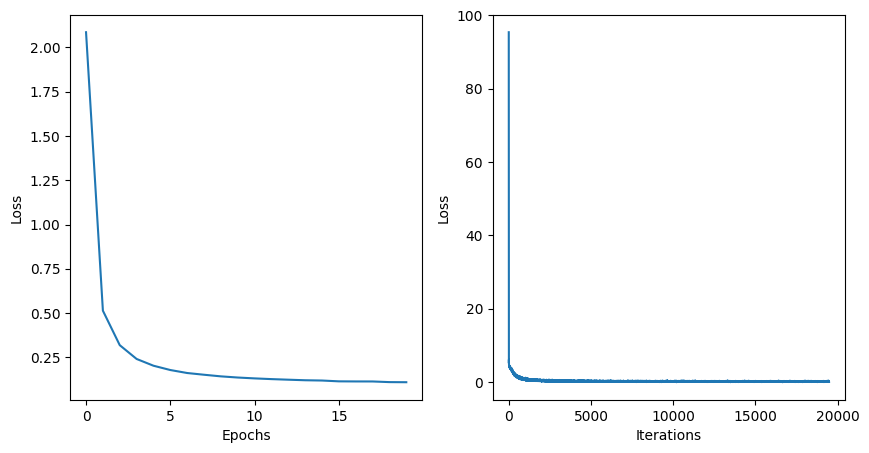

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

ax1.plot(epoch_losses)
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Loss")

ax2.plot(iteration_losses)
ax2.set_xlabel("Iterations")
ax2.set_ylabel("Loss")

plt.show()

In [27]:
def decode_predictions(text_batch_logits):

    text_batch_tokens = F.softmax(text_batch_logits, 2).argmax(2) # [T, batch_size]
    text_batch_tokens = text_batch_tokens.numpy().T # [batch_size, T]

    text_batch_tokens_new = []
    for text_tokens in text_batch_tokens:
        text = [idx2char[idx] for idx in text_tokens]
        text = "".join(text)
        text_batch_tokens_new.append(text)

    return text_batch_tokens_new

In [ ]:
# torch.save(crnn.state_dict(), './Model/ocr_model.pth')

In [28]:
results_train = pd.DataFrame(columns=['actual', 'prediction'])
train_loader = DataLoader(trainset, batch_size=16, num_workers=1, shuffle=False)
with torch.no_grad():
    for image_batch, text_batch in tqdm(train_loader, leave=True):
        text_batch_logits = crnn(image_batch.to(device)) # [T, batch_size, num_classes==num_features]
        text_batch_pred = decode_predictions(text_batch_logits.cpu())
        #print(text_batch, text_batch_pred)
        dfs = pd.DataFrame(columns=['actual', 'prediction'])
        dfs['actual'] = text_batch
        dfs['prediction'] = text_batch_pred
        results_train = pd.concat([results_train, dfs])
results_train = results_train.reset_index(drop=True)

  0%|          | 0/974 [00:00<?, ?it/s]

In [29]:
def remove_duplicates(text):
    if len(text) > 1:
        letters = [text[0]] + [letter for idx, letter in enumerate(text[1:], start=1) if text[idx] != text[idx-1]]
    elif len(text) == 1:
        letters = [text[0]]
    else:
        return ""
    return "".join(letters)

def correct_prediction(word):
    parts = word.split("-")
    parts = [remove_duplicates(part) for part in parts]
    corrected_word = "".join(parts)
    return corrected_word

In [30]:
results_train['prediction_corrected'] = results_train['prediction'].apply(correct_prediction)
results_train.head()

,actual,prediction,prediction_corrected
0,ប្រភពបន្ថែមថា៖,!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!...,!ប្រភ!ព!ប!ន្ថែម!ថា!៖!
1,លោកPatrickMahoneyគាំទ្រនិងលើកទឹកចិត្តនិស្សិតដែ...,!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!...,!ល!ោ!ក!P!a!rick!M!a!h!o!n!ey!គាំទ្រ!និង!លើក!ទឹ...
2,ការវិនិយោគប្រចាំឆ្នាំខាងបច្ចេកវិទ្យាមានដូចជាបន...,!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!...,!ក!ា!រវិនិ!យ!ោ!គ!ប្រ!ចាំឆ្នាំខា!ង!ប!ច្ចេក!វិទ!...
3,តាមដានព័ត៌មានទាំងអស់ដែលអ្នកត្រូវការជាមួយនឹងវាល...,!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!...,!ត!ា!ម!ដ!ា!ន!ព័!ត៌!មា!ន!ទ!ាំង!អ!ស់!ដែ!ល!អ្ន!ក!...
4,បញ្ជាការផ្លាស់ប្តូរV,!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!...,!ប!ញ្ជា!ក!ារផ្លាស់ប្តូរ!V!


In [36]:
import os
import torch
import pandas as pd
from PIL import Image
import torch.nn.functional as F
from torchvision import transforms

# Define the transformation operations
transform_ops = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
])

# Function to remove duplicates in the predicted text
def remove_duplicates(text):
    if len(text) > 1:
        letters = [text[0]] + [letter for idx, letter in enumerate(text[1:], start=1) if text[idx] != text[idx-1]]
    elif len(text) == 1:
        letters = [text[0]]
    else:
        return ""
    return "".join(letters)

# Function to correct the predicted word
def correct_prediction(word):
    parts = word.split("-")
    parts = [remove_duplicates(part) for part in parts]
    corrected_word = "".join(parts)
    return corrected_word

# Function to decode predictions from logits
def decode_predictions(text_batch_logits):
    text_batch_tokens = F.softmax(text_batch_logits, 2).argmax(2)  # [T, batch_size]
    text_batch_tokens = text_batch_tokens.numpy().T  # [batch_size, T]

    text_batch_tokens_new = []
    for text_tokens in text_batch_tokens:
        text = [idx2char[idx] for idx in text_tokens]
        text = "".join(text)
        text_batch_tokens_new.append(text)

    return text_batch_tokens_new

# Inference function
def infer_image(image_path, model, device):
    # Load and preprocess the image
    image = Image.open(image_path).convert("RGB")
    image = transform_ops(image).unsqueeze(0).to(device)  # Add batch dimension

    # Perform inference
    model.eval()
    with torch.no_grad():
        text_logits = model(image)  # [T, batch_size, num_classes]
        text_logits = text_logits.cpu()

    # Decode predictions
    text_pred = decode_predictions(text_logits)[0]

    # Apply post-processing corrections
    text_pred_corrected = correct_prediction(text_pred)

    return text_pred_corrected

# Directory containing images
image_directory = '/home/ubuntu-vilalab/Desktop/setthika/ocr/new_dataset_daunpenh/images/Daunpenh'

# Model initialization and loading weights
# model = OCR_CNN_GRU(num_chars=167, rnn_hidden_size=512, dropout=0.5)  # Replace with your model initialization
# model.load_state_dict(torch.load('path/to/your/model.pth'))  # Load the trained model weights
# model.to(device)

# Iterate over all images in the directory and perform inference
results = []
for filename in os.listdir(image_directory):
    if filename.endswith('.png') or filename.endswith('.jpg'):
        image_path = os.path.join(image_directory, filename)
        predicted_text = infer_image(image_path, crnn, device)
        results.append({'filename': filename, 'predicted_text': predicted_text})

# Convert the results to a DataFrame and save to a CSV file
dfss = pd.DataFrame(results)
# csv_path = 'predictions.csv'
# df.to_csv(csv_path, index=False)

# print(f'Predictions saved to {csv_path}')


In [37]:
def remove_sign(text):
    text = text.replace("!","")
    return text
dfss["predicted_text"] = dfss["predicted_text"].apply(remove_sign)
dfss

,filename,predicted_text
0,Khmer_txt_2114.png,aaitfviriviairirivf
1,Khmer_txt_3718.png,ri
2,Khmer_txt_281.png,ifvifrirfriairrfiarriirrit
3,Khmer_txt_6406.png,zv
4,Khmer_txt_4703.png,x
...,...,...
7255,Khmer_txt_2378.png,arrriធiria
7256,Khmer_txt_2484.png,ifafrffrfiai
7257,Khmer_txt_2606.png,firirirvfrviffvៈ
7258,Khmer_txt_4681.png,art៖


In [ ]:
df